# **Phase 2: December 2017 Analysis**

This notebook answers four business questions about Seoul Bike Rentals in December 2017. Each question has a dashboard and a plain-language answer built from the data, so the numbers always match the charts.

| Question | Topic |
|---|---|
| 1 | How did daily rentals move, and which days stand out? |
| 2 | What does a typical day look like by hour? |
| 3 | How do weeks and weekdays compare? |
| 4 | Did weather explain the weak days? |

## **Step 0: Import all Necessary Libraries**

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt

sys.path.append("..")

from src.clean import (
    load_clean,
    CLEAN_FILE,
    CLOSED_LABEL,
    HOURS_PER_DAY,
    MIN_HOUR,
    MAX_HOUR
)

from src.analysis import (
    daily_totals,
    hour_profile,
    daily_table,
    weekly_summary,
    weekday_summary,
    week_weekday_matrix,
    hour_profile_by_day_type,
    date_hour_matrix,
    time_block_share,
    peak_hours,
    daily_weather,
)

from src.dashboards import (
    dashboard_daily,
    dashboard_hourly,
    dashboard_weekly,
    dashboard_weather,
)

CLEAN_DIR = Path("../data/clean")
FIG_DIR = Path("../reports/figures")
TABLE_DIR = Path("../reports/tables")

PERIOD = "December 2017"

## **Step 1: Load and Filter the Data**

In [2]:
clean_df = load_clean(CLEAN_DIR / CLEAN_FILE)

# mask out year and month
is_dec_2017 = (clean_df["year"] == 2017) & (clean_df["month"] == 12)

# The filter names both year and month. If the file later gains November 2017 rows,
# a year-only filter pulls them into the December report.
# If it gains December 2018, a month-only filter mixes the two Decembers.
dec17 = clean_df[is_dec_2017].copy()

## **Step 2: Assertions**

In [3]:
DAYS_IN_MONTH = 31          # unique number of dates in December

# Check 1: Row count
EXPECTED_DEC_ROWS = 744      # DAYS_IN_MONTH * HOURS_PER_DAY
assert len(dec17) == EXPECTED_DEC_ROWS, (
    f"Expected {EXPECTED_DEC_ROWS} rows, got {len(dec17)}"
)

# Check 2: Unique dates
unique_dates = dec17["date"].nunique()
assert unique_dates == DAYS_IN_MONTH, (
    f"Expected {DAYS_IN_MONTH} unique dates, got {unique_dates}"
)

# Check 3: Hours (Min, Max)
dec17_min_hour = dec17["hour"].min()
assert dec17_min_hour == MIN_HOUR, (
    f"Expected minimum hour {MIN_HOUR}, got {dec17_min_hour}"
)

dec17_max_hour = dec17["hour"].max()
assert dec17_max_hour == MAX_HOUR, (
    f"Expected maximum hour {MAX_HOUR}, got {dec17_max_hour}"
)

dec17_hours_per_day = dec17["hour"].nunique()
assert dec17_hours_per_day == HOURS_PER_DAY, (
    f"Expected {HOURS_PER_DAY} distinct hours, got {dec17_hours_per_day}"
)

# Check 4: Closed hours
# The file on disk is made by split_closed in notebook 01.
# This assert proves the file holds open hours only. It does not prove split_closed worked.
EXPECTED_CLOSED_HOUR = 0
closed_hours = (dec17["functioning_day"] == CLOSED_LABEL).sum()
assert closed_hours == EXPECTED_CLOSED_HOUR, (
    f"Expected {EXPECTED_CLOSED_HOUR} closed hours, got {closed_hours}"
)

# Check 5: Season
EXPECTED_SEASONS_COUNT = 1
season_count = dec17["seasons"].nunique()
assert season_count == EXPECTED_SEASONS_COUNT, (
    f"Expected {EXPECTED_SEASONS_COUNT} distinct season, got {season_count}"
)

EXPECTED_SEASONS = {"Winter"}
seasons = set(dec17["seasons"].unique().tolist())
assert seasons == EXPECTED_SEASONS, (
    f"Expected {EXPECTED_SEASONS}, got {seasons}"
)

print("All assertions passed.")

All assertions passed.


## **Step 3: Build the Analysis Tables**

Every dashboard reads from these tables. Cross-checks below prove the tables agree with the raw rows.

In [4]:
daily = daily_table(dec17)              # one row per date
weekly = weekly_summary(daily)          # one row per week (Friday to Thursday)
weekday = weekday_summary(daily)        # one row per weekday
profile = hour_profile(dec17)           # mean rentals per hour

# Cross-checks
assert daily["daily_rentals"].sum() == dec17["rented_bike_count"].sum()
assert (daily["daily_rentals"].values == daily_totals(dec17).values).all()
assert weekly["days"].sum() == DAYS_IN_MONTH
assert weekday["days"].sum() == DAYS_IN_MONTH

display(weekly.round({"mean_daily_rentals": 1, "change_vs_prev_pct": 1}))
display(weekday.round({"mean_daily_rentals": 1}))

,week_number,start_date,end_date,days,total_rentals,mean_daily_rentals,is_partial,change_vs_prev_pct
0,1,2017-12-01,2017-12-07,7,57538,8219.7,False,NaN
1,2,2017-12-08,2017-12-14,7,42479,6068.4,False,-26.2
2,3,2017-12-15,2017-12-21,7,32862,4694.6,False,-22.6
3,4,2017-12-22,2017-12-28,7,37338,5334.0,False,13.6
4,5,2017-12-29,2017-12-31,3,15113,5037.7,True,-5.6


,day_name,days,mean_daily_rentals,min_rentals,max_rentals
0,Friday,5,7923.2,7184,9539
1,Saturday,5,6207.8,4027,8523
2,Sunday,5,3977.6,2014,7222
3,Monday,4,5290.8,2620,8729
4,Tuesday,4,5935.5,4334,8307
5,Wednesday,4,5651.8,4568,6669
6,Thursday,4,6818.8,5734,8549


## **Question 1: How did daily rentals move in December 2017, and which days stand out?**

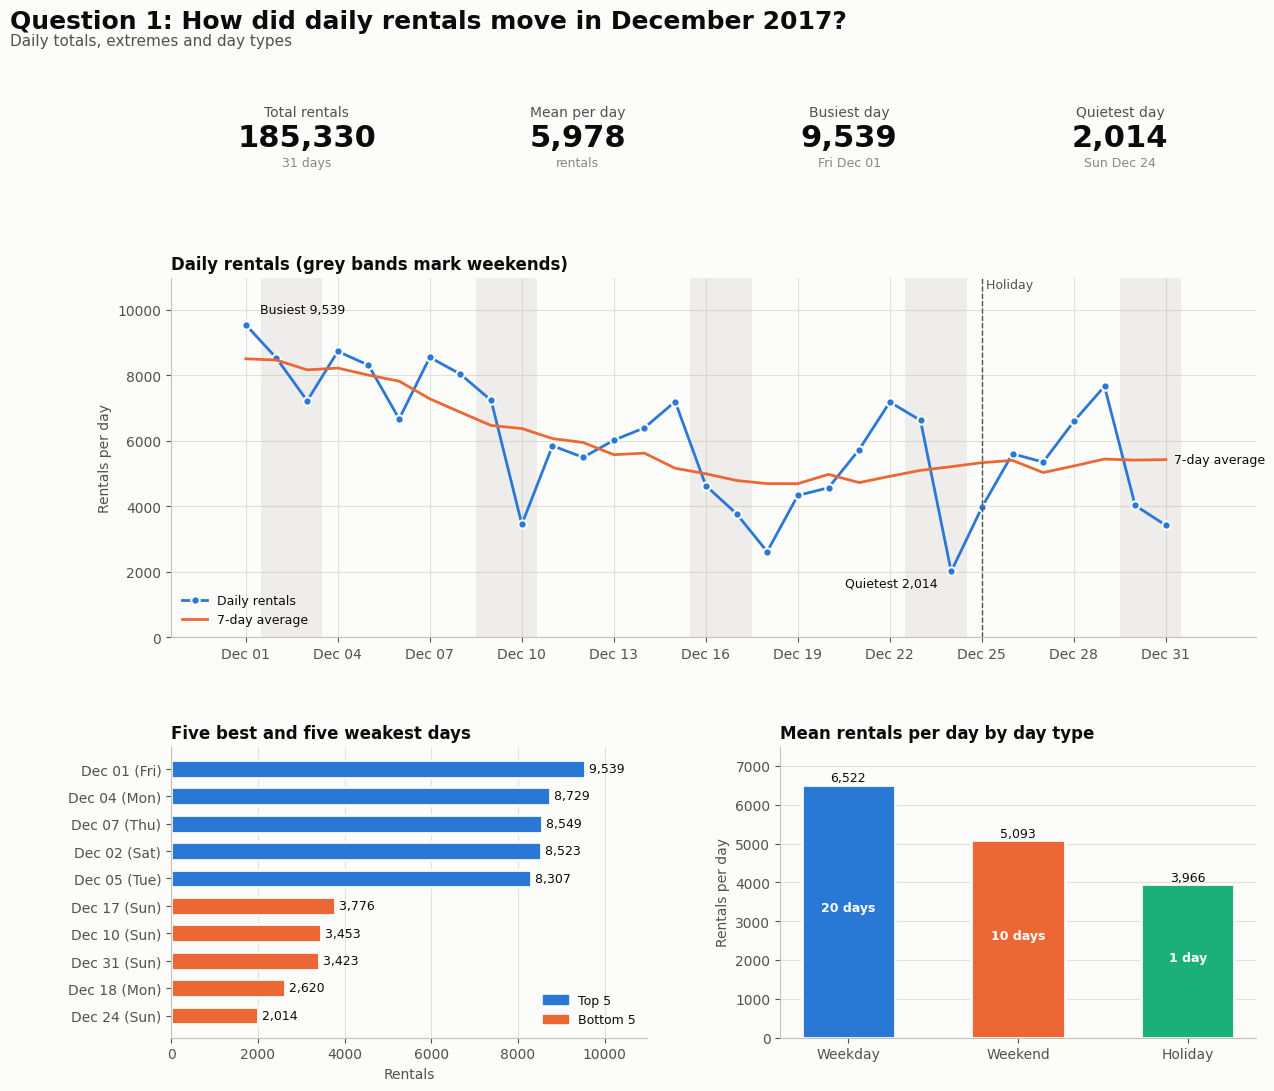

In [5]:
dashboard_daily(daily, PERIOD, FIG_DIR / "q1_daily_dashboard_2017.png");

In [6]:
total = int(daily["daily_rentals"].sum())
mean_day = daily["daily_rentals"].mean()
busiest = daily.loc[daily["daily_rentals"].idxmax()]
quietest = daily.loc[daily["daily_rentals"].idxmin()]

print(f"{PERIOD} had {total:,} rentals over {len(daily)} days, a mean of {mean_day:,.0f} per day.")
print(f"Busiest day: {busiest['date']:%A %d %B} with {busiest['daily_rentals']:,} rentals.")
print(f"Quietest day: {quietest['date']:%A %d %B} with {quietest['daily_rentals']:,} rentals.")

half = len(daily) // 2
first_half = daily["daily_rentals"].iloc[:half].mean()
second_half = daily["daily_rentals"].iloc[half:].mean()
change = (second_half / first_half - 1) * 100
print(f"Days 1 to {half} averaged {first_half:,.0f} per day. Days {half + 1} to {len(daily)} averaged {second_half:,.0f} per day ({change:+.0f}%).")

by_type = daily.groupby("day_type")["daily_rentals"].mean()
if {"Weekday", "Weekend"} <= set(by_type.index):
    gap = (by_type["Weekend"] / by_type["Weekday"] - 1) * 100
    print(f"Weekend days averaged {by_type['Weekend']:,.0f} against {by_type['Weekday']:,.0f} on weekdays ({gap:+.0f}%).")

for _, row in daily[daily["day_type"] == "Holiday"].iterrows():
    same = daily[(daily["day_name"] == row["day_name"]) & (daily["day_type"] != "Holiday")]["daily_rentals"].mean()
    gap = (row["daily_rentals"] / same - 1) * 100
    print(f"Holiday {row['date']:%d %B}: {row['daily_rentals']:,} rentals, {gap:+.0f}% against the mean of other {row['day_name']}s ({same:,.0f}).")

December 2017 had 185,330 rentals over 31 days, a mean of 5,978 per day.
Busiest day: Friday 01 December with 9,539 rentals.
Quietest day: Sunday 24 December with 2,014 rentals.
Days 1 to 15 averaged 7,148 per day. Days 16 to 31 averaged 4,882 per day (-32%).
Weekend days averaged 5,093 against 6,522 on weekdays (-22%).
Holiday 25 December: 3,966 rentals, -31% against the mean of other Mondays (5,732).


## **Question 2: What does a typical day look like by hour, and when are the peaks?**

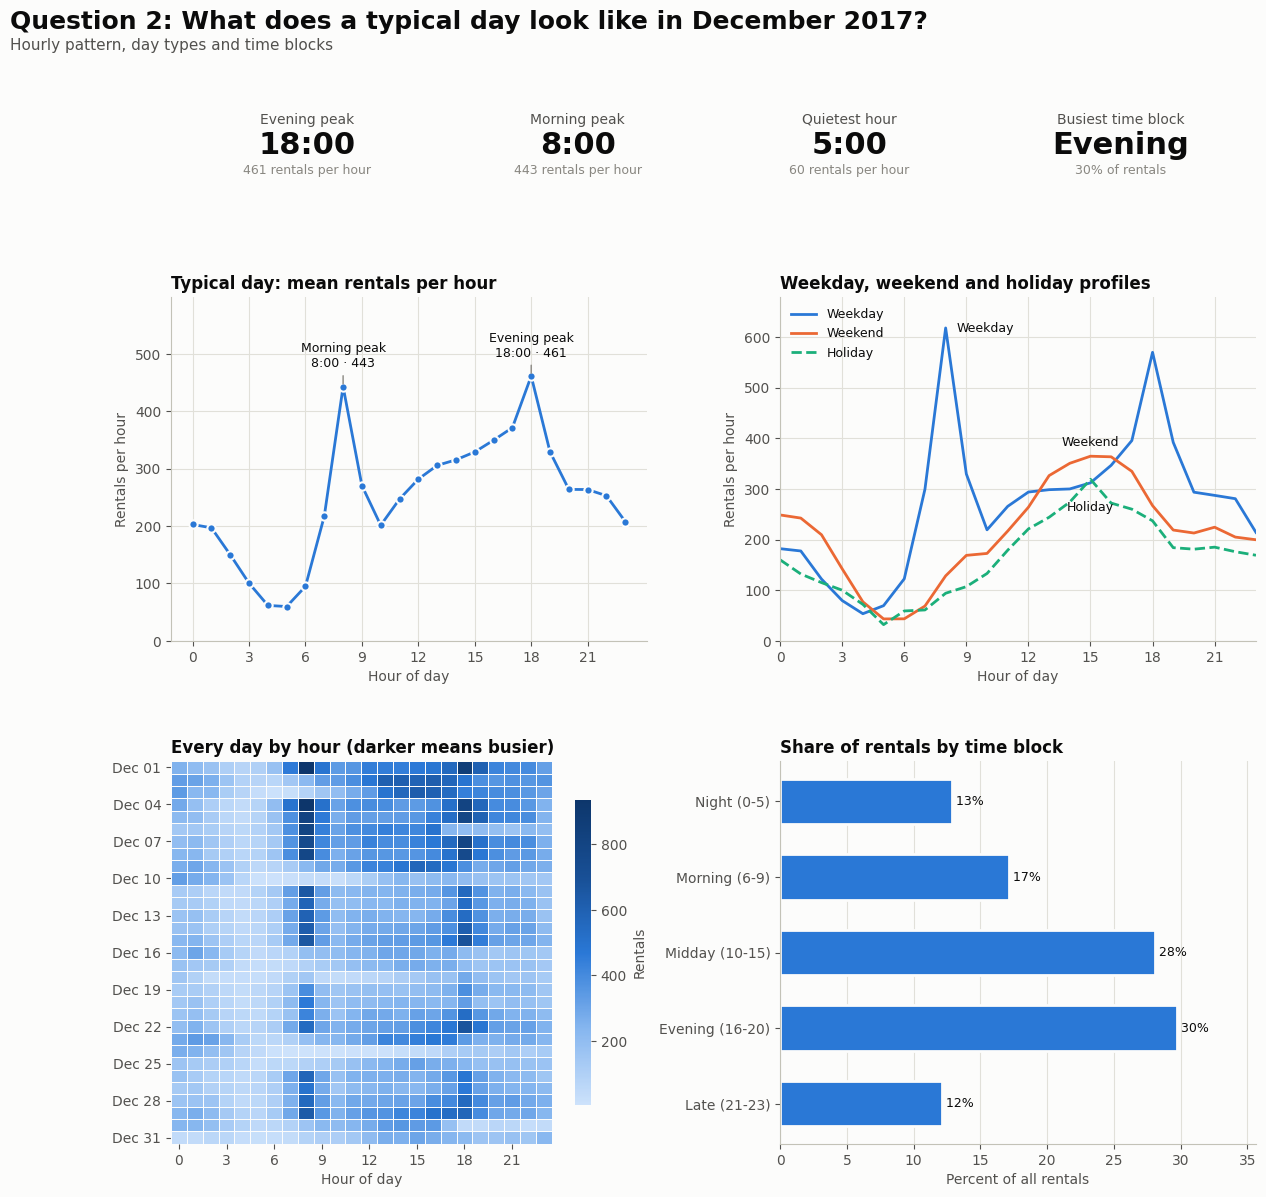

In [7]:
by_type_hour = hour_profile_by_day_type(dec17)
shares = time_block_share(dec17)
hour_matrix = date_hour_matrix(dec17)
peaks = peak_hours(profile)

dashboard_hourly(
    profile, by_type_hour, shares, hour_matrix, peaks,
    PERIOD, FIG_DIR / "q2_hourly_dashboard_2017.png"
);

In [8]:
print(f"Evening peak: {peaks['evening_hour']}:00 with {peaks['evening_mean']:,.0f} rentals per hour.")
print(f"Morning peak: {peaks['morning_hour']}:00 with {peaks['morning_mean']:,.0f} rentals per hour.")
print(f"Quietest hour: {peaks['trough_hour']}:00 with {peaks['trough_mean']:,.0f} rentals per hour.")
print(f"{shares.idxmax()} holds the largest share of rentals at {shares.max():.0f}%.")

print()
for day_type in by_type_hour.columns:
    p = by_type_hour[day_type]
    morning, evening = p.loc[6:11], p.loc[16:21]
    print(f"{day_type}: morning peak {morning.idxmax()}:00 ({morning.max():,.0f}), evening peak {evening.idxmax()}:00 ({evening.max():,.0f}).")

if {"Weekday", "Weekend"} <= set(by_type_hour.columns):
    hour = int(by_type_hour["Weekday"].loc[6:11].idxmax())
    ratio = by_type_hour["Weekday"].loc[hour] / by_type_hour["Weekend"].loc[hour]
    print()
    print(f"At {hour}:00 weekday rentals run {ratio:.1f} times the weekend rate. Two weekday peaks point to commuting.")

Evening peak: 18:00 with 461 rentals per hour.
Morning peak: 8:00 with 443 rentals per hour.
Quietest hour: 5:00 with 60 rentals per hour.
Evening (16-20) holds the largest share of rentals at 30%.

Holiday: morning peak 11:00 (179), evening peak 16:00 (272).
Weekday: morning peak 8:00 (618), evening peak 18:00 (570).
Weekend: morning peak 11:00 (217), evening peak 16:00 (363).

At 8:00 weekday rentals run 4.8 times the weekend rate. Two weekday peaks point to commuting.


## **Question 3: How do weeks and weekdays compare?**

Weeks run Friday to Thursday. Week 5 holds only three days, so the dashboard compares **mean rentals per day**, not weekly totals.

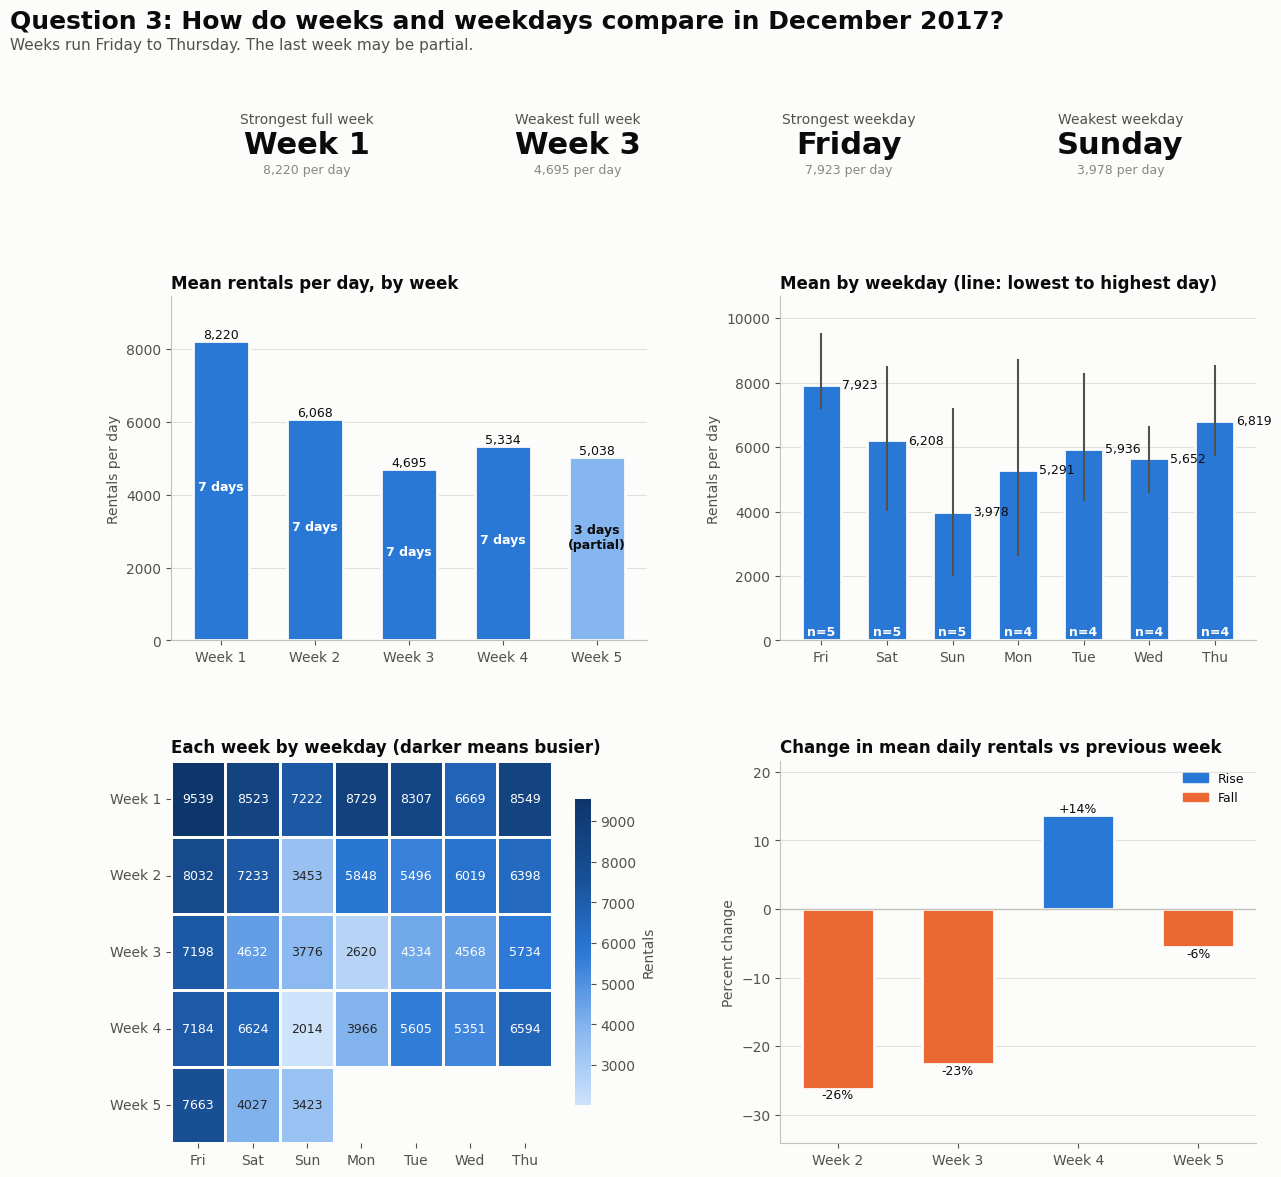

In [9]:
matrix = week_weekday_matrix(daily)

dashboard_weekly(
    daily, weekly, weekday, matrix,
    PERIOD, FIG_DIR / "q3_weekly_dashboard_2017.png"
);

In [10]:
for _, w in weekly.iterrows():
    tag = " (partial)" if w["is_partial"] else ""
    print(f"Week {int(w['week_number'])}{tag}: {w['start_date']:%b %d} to {w['end_date']:%b %d}, "
          f"{int(w['days'])} days, mean {w['mean_daily_rentals']:,.0f} per day.")

full_weeks = weekly[~weekly["is_partial"]]
first, last_full = full_weeks.iloc[0], full_weeks.iloc[-1]
change = (last_full["mean_daily_rentals"] / first["mean_daily_rentals"] - 1) * 100
print()
print(f"From week {int(first['week_number'])} to week {int(last_full['week_number'])}, mean daily rentals changed {change:+.0f}%.")

best = weekday.loc[weekday["mean_daily_rentals"].idxmax()]
weakest = weekday.loc[weekday["mean_daily_rentals"].idxmin()]
print(f"Strongest weekday: {best['day_name']} at {best['mean_daily_rentals']:,.0f} per day.")
print(f"Weakest weekday: {weakest['day_name']} at {weakest['mean_daily_rentals']:,.0f} per day.")
print(f"Each weekday appears {int(weekday['days'].min())} or {int(weekday['days'].max())} times, so check this ranking against 2018 before you call it a rule.")

Week 1: Dec 01 to Dec 07, 7 days, mean 8,220 per day.
Week 2: Dec 08 to Dec 14, 7 days, mean 6,068 per day.
Week 3: Dec 15 to Dec 21, 7 days, mean 4,695 per day.
Week 4: Dec 22 to Dec 28, 7 days, mean 5,334 per day.
Week 5 (partial): Dec 29 to Dec 31, 3 days, mean 5,038 per day.

From week 1 to week 4, mean daily rentals changed -35%.
Strongest weekday: Friday at 7,923 per day.
Weakest weekday: Sunday at 3,978 per day.
Each weekday appears 4 or 5 times, so check this ranking against 2018 before you call it a rule.


## **Question 4: Did weather explain the weak days?**

The dashboard places rentals above temperature on the same dates, then tests temperature, rain and snow against daily rentals.

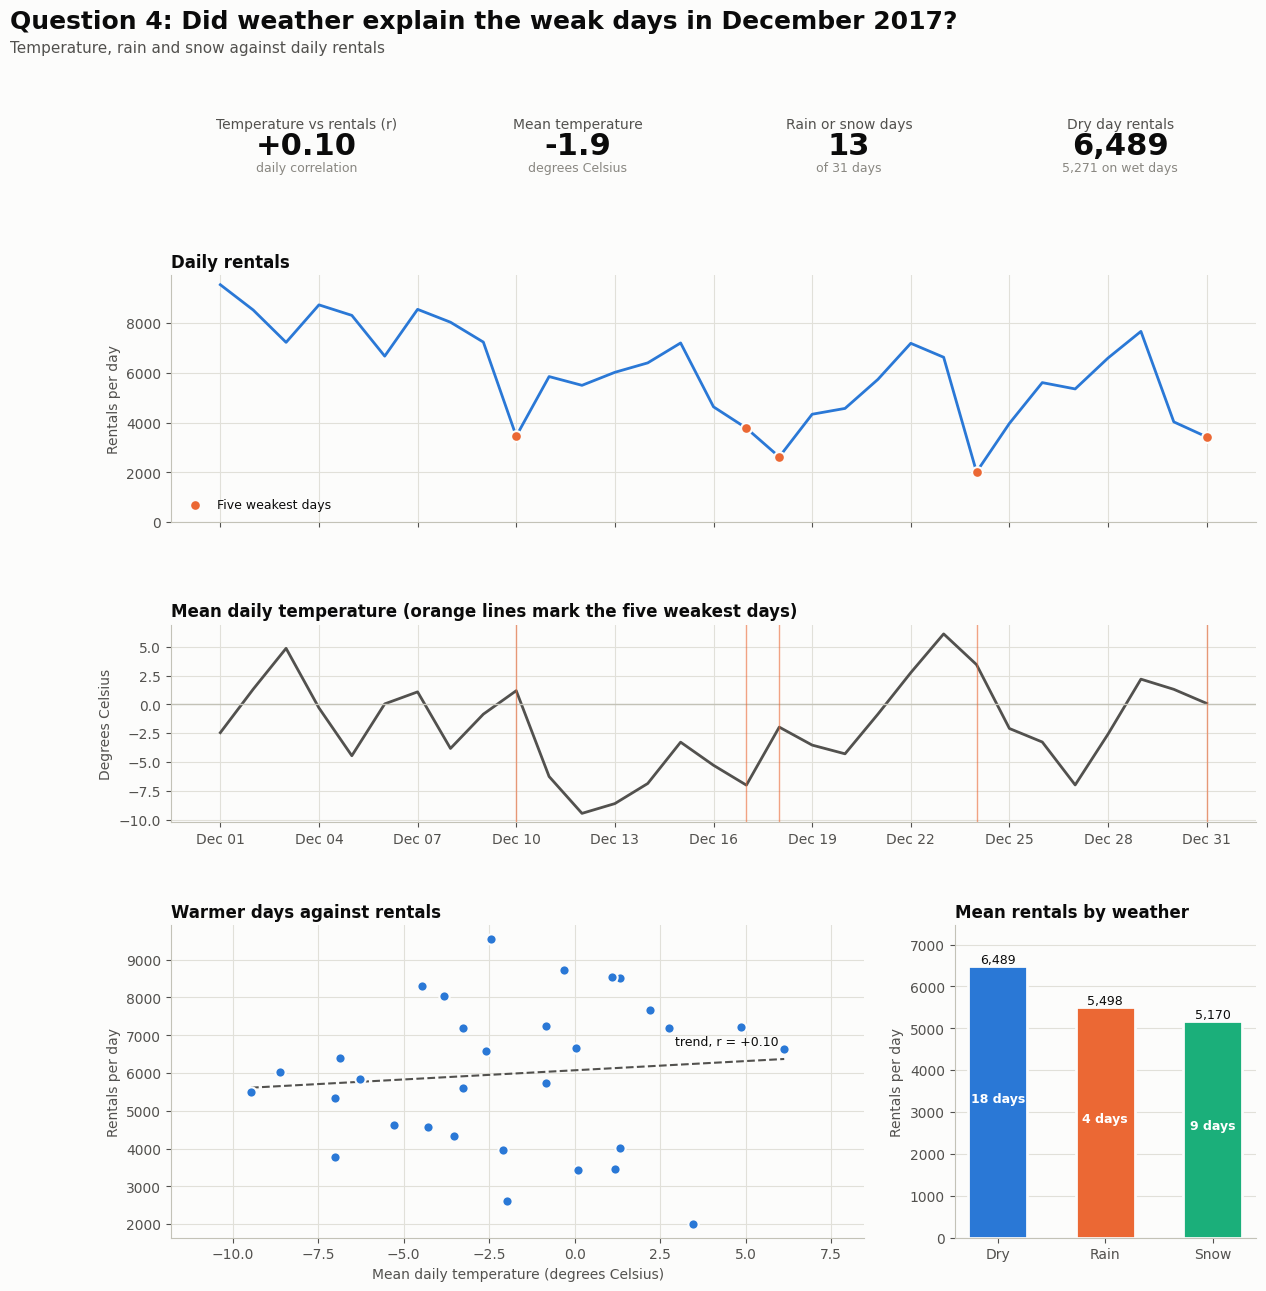

In [11]:
weather = daily_weather(dec17)
needed = {"temperature", "rainfall", "snowfall"}
missing = needed - set(weather.columns)
weather_ok = not missing

if weather_ok:
    weather_view = daily.merge(weather, on="date")
    dashboard_weather(weather_view, PERIOD, FIG_DIR / "q4_weather_dashboard_2017.png");
else:
    print(f"Weather columns not found: {sorted(missing)}")
    print(f"Columns in the file: {list(dec17.columns)}")

In [12]:
if weather_ok:
    corr = weather_view["temperature"].corr(weather_view["daily_rentals"])
    print(f"Temperature against daily rentals: r = {corr:+.2f}.")
    print(f"Rain fell on {(weather_view['rainfall'] > 0).sum()} days. Snow fell on {(weather_view['snowfall'] > 0).sum()} days.")

    wet = weather_view[(weather_view["rainfall"] > 0) | (weather_view["snowfall"] > 0)]
    dry = weather_view.drop(wet.index)
    if len(wet) and len(dry):
        print(f"Dry days averaged {dry['daily_rentals'].mean():,.0f} rentals. Wet days averaged {wet['daily_rentals'].mean():,.0f}.")

    weakest_five = weather_view.nsmallest(5, "daily_rentals")
    sundays = int((weakest_five["day_name"] == "Sunday").sum())
    print(f"{sundays} of the five weakest days were Sundays, so the day of the week matters as much as the weather.")

    # Fair test: compare wet and dry days within weekdays only.
    wd = weather_view[weather_view["day_type"] == "Weekday"]
    wd_wet = wd[(wd["rainfall"] > 0) | (wd["snowfall"] > 0)]["daily_rentals"]
    wd_dry = wd[(wd["rainfall"] == 0) & (wd["snowfall"] == 0)]["daily_rentals"]
    if len(wd_wet) and len(wd_dry):
        print(f"Weekdays only: dry days averaged {wd_dry.mean():,.0f} ({len(wd_dry)} days), wet days averaged {wd_wet.mean():,.0f} ({len(wd_wet)} days).")

    print()
    print("Five weakest days and their weather:")
    display(
        weakest_five
        [["date", "day_name", "daily_rentals", "temperature", "rainfall", "snowfall"]]
        .round({"temperature": 1, "rainfall": 1, "snowfall": 1})
    )

Temperature against daily rentals: r = +0.10.
Rain fell on 9 days. Snow fell on 9 days.
Dry days averaged 6,489 rentals. Wet days averaged 5,271.
4 of the five weakest days were Sundays, so the day of the week matters as much as the weather.
Weekdays only: dry days averaged 6,838 (12 days), wet days averaged 6,048 (8 days).

Five weakest days and their weather:


,date,day_name,daily_rentals,temperature,rainfall,snowfall
23,2017-12-24,Sunday,2014,3.5,20.0,0.0
17,2017-12-18,Monday,2620,-2.0,3.4,59.7
30,2017-12-31,Sunday,3423,0.1,1.2,14.3
9,2017-12-10,Sunday,3453,1.2,4.1,32.5
16,2017-12-17,Sunday,3776,-7.0,0.0,0.0


## **Step 4: Save Tables for the Report**

In [13]:
TABLE_DIR.mkdir(parents=True, exist_ok=True)

daily.to_csv(TABLE_DIR / "dec17_daily.csv", index=False)
weekly.to_csv(TABLE_DIR / "dec17_weekly.csv", index=False)
weekday.to_csv(TABLE_DIR / "dec17_weekday.csv", index=False)
profile.rename("mean_rentals").to_csv(TABLE_DIR / "dec17_hourly.csv")

print("Tables saved to", TABLE_DIR.resolve())
print("Dashboards saved to", FIG_DIR.resolve())

Tables saved to C:\Users\USER\OneDrive\Desktop\SeoulBikeRentals\reports\tables
Dashboards saved to C:\Users\USER\OneDrive\Desktop\SeoulBikeRentals\reports\figures
